# Image Data · Part 1: Fashion-MNIST — Image Feature Discovery & Classical Computer Vision

**Goal:** Tackle a **10-class image classification** problem (**Fashion-MNIST** — 28×28 grayscale clothing photos) using **Classical Machine Learning & Computer Vision** on your Vulkan GPU!

In Notebooks #1 & #2, we predicted a continuous number (*regression*). Now we're classifying **images into 10 clothing categories** (`T-shirt`, `Trouser`, `Pullover`, `Dress`, `Coat`, `Sandal`, `Shirt`, `Sneaker`, `Bag`, `Ankle boot`):

1. **Load & Inspect** the official Zalando Fashion-MNIST images (12,000 train / 2,000 test stratified split).
2. **Visual EDA:** Look at sample images AND compute the **"Average Clothing" prototype** for each class on GPU.
3. **Raw Baseline:** Flatten every 28×28 image into 784 numbers and train a **One-vs-Rest GPU `LogisticRegression`** classifier.
4. **Classical CV Feature Discovery:** Compress images into **"Eigen-Clothes"** with GPU `vklearn.PCA`, then hand-engineer **Sobel-style edge & gradient features** (how computer vision worked *before* CNNs!).
5. **Classical ML Bake-Off & Error Analysis:** Compare Linear vs. PCA vs. GPU `KNeighborsClassifier`, inspect the **10×10 Confusion Matrix**, and see the exact mistakes Classical ML makes.

> **Coming next in Notebook #4:** We'll train a **`vktorch` 2D Convolutional Neural Network (`Conv2d` + `MaxPool2d`)** on this exact same 12,000 / 2,000 split to see why CNNs revolutionized computer vision!


> **Where Image AI (Computer Vision) Is Used in the Real World:**
> - **Companies & Products:** Self-driving lane/object detection (**Tesla, Waymo**), visual search & Face ID (**Apple, Pinterest, Google Lens**), and medical MRI/X-ray screening.
> - **Popular Algorithms:** Classical `PCA` + `HOG` edge descriptors (this chapter), 2D `CNN`s (**ResNet, YOLO, ConvNeXt** — Chapter 4!), and Vision Transformers (**ViT**).


In [1]:
import sys, time
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from IPython.display import display

import vknumpy as vnp
import vklearn as vkl
import vkplot

# 1. Load & cache official Zalando Fashion-MNIST directly onto the Vulkan GPU
# Deterministic stratified split (12,000 train = 1,200/class, 2,000 test = 200/class)
# Same exact split will be used in Notebook #4 (vktorch CNN)!
X_tr_img, y_tr, X_te_img, y_te, CLASS_NAMES = vkl.load_fashion_mnist(
    per_class_train=1200, per_class_test=200, seed=42
)

print(f"Loaded Fashion-MNIST on Vulkan GPU! Train: {X_tr_img.shape}, Test: {X_te_img.shape}")
print("Classes (balanced):", {CLASS_NAMES[c]: int(vnp.sum(y_tr == c)) for c in range(10)})


Loaded Fashion-MNIST on Vulkan GPU! Train: (12000, 28, 28), Test: (2000, 28, 28)
Classes (balanced): {'T-shirt': 1200, 'Trouser': 1200, 'Pullover': 1200, 'Dress': 1200, 'Coat': 1200, 'Sandal': 1200, 'Shirt': 1200, 'Sneaker': 1200, 'Bag': 1200, 'Ankle boot': 1200}


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


---
## Step 1: Visual EDA — Sample Gallery & "Average Clothing" Prototypes

Let's look at 8 real examples from each class, plus the **mean image** of every class (computed on GPU). Notice how crisp `Trouser`, `Sandal`, and `Ankle boot` are — while `T-shirt`, `Pullover`, `Coat`, and `Shirt` look almost like blurry ghosts of each other! That's a huge clue about where Classical ML will struggle.


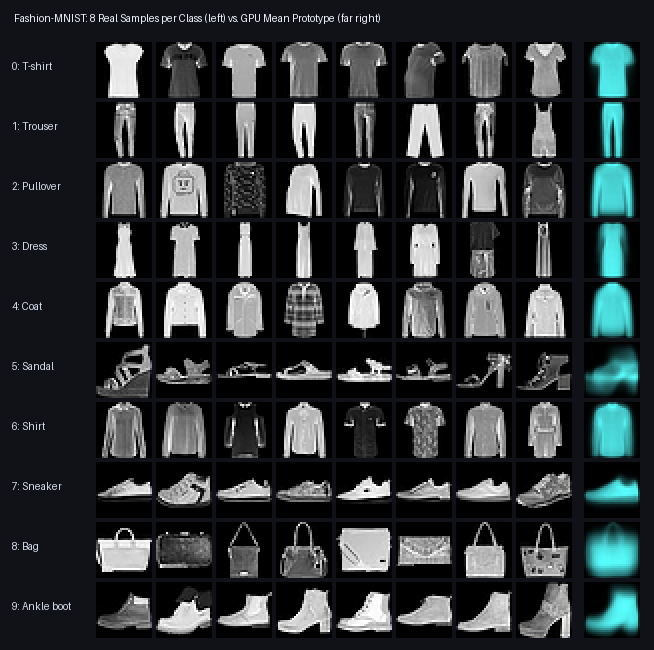

In [2]:
# Render 10 rows (classes) x 9 cols (8 real samples + 1 GPU mean prototype) in 1 line!
display(vkplot.class_gallery(
    X_tr_img, y_tr, CLASS_NAMES, n_samples=8, show_mean=True, scale=2,
    title="Fashion-MNIST: 8 Real Samples per Class (left) vs. GPU Mean Prototype (far right)",
))


---
## Step 2: Baseline — One-vs-Rest GPU `LogisticRegression` on 784 Raw Pixels

Classical tabular classifiers don't understand 2D images, so the simplest baseline is to **flatten** each `28 × 28` image into a flat vector of **784 pixel brightness numbers**.

Because `vklearn.LogisticRegression` is a binary (`0` vs `1`) classifier, we use **One-vs-Rest (OvR)** — train 10 binary classifiers (`Is this a T-shirt?`, `Is this a Trouser?`, ...) on Vulkan GPU and pick whichever class outputs the highest probability!


In [3]:
X_tr_flat = X_tr_img.reshape(len(X_tr_img), 784)
X_te_flat = X_te_img.reshape(len(X_te_img), 784)

def fit_predict_ovr_logreg(X_tr_arr, y_tr_arr, X_te_arr, C=0.5, max_iter=35):
    """10-class One-vs-Rest LogisticRegression on Vulkan GPU."""
    t0 = time.perf_counter()
    sc = vkl.StandardScaler().fit(X_tr_arr)
    Xtr_s = sc.transform(X_tr_arr)
    Xte_s = sc.transform(X_te_arr)
    cols = []
    for c in range(10):
        clf = vkl.LogisticRegression(C=C, max_iter=max_iter)
        clf.fit(Xtr_s, y_tr_arr == c)
        p = clf.predict_proba(Xte_s)
        cols.append(p[:, 1] if p.ndim == 2 else p)
    probs = vnp.column_stack(cols)
    preds = vnp.argmax(probs, axis=1)
    return preds, (time.perf_counter() - t0)

pred_raw_lr, dt_raw_lr = fit_predict_ovr_logreg(X_tr_flat, y_tr, X_te_flat, C=0.2, max_iter=25)
acc_raw_lr = float(vkl.accuracy_score(y_te, pred_raw_lr))
print(f"1. Baseline OvR LogisticRegression (784 raw pixels): Test Accuracy = {acc_raw_lr:.2%} ({dt_raw_lr:.2f}s)")


1. Baseline OvR LogisticRegression (784 raw pixels): Test Accuracy = 81.50% (15.55s)


---
## Step 3: Classical Image Feature Discovery (PCA "Eigen-Clothes" + Hand-Crafted Edges!)

Before Deep Learning and CNNs took over, how did engineers make classical ML better at images? Two classic techniques:

1. **PCA ("Eigen-Clothes") via `vklearn.PCA`:** Most of the 784 pixels are correlated (neighboring pixels have similar brightness, and the corners are almost always black!). PCA compresses 784 pixels into the **64 most informative visual patterns** ("eigen-clothes"), removing pixel noise and making distance-based models like KNN much sharper and faster.
2. **Hand-Crafted Edge & Spatial Features (mini-HOG!):** Shape matters more than raw brightness! A dark coat and a light coat have completely different pixel values, but the **exact same outline (edges)**. So we compute:
   - Horizontal edges (`dx = img[:, :, 1:] - img[:, :, :-1]`)
   - Vertical edges (`dy = img[:, 1:, :] - img[:, :-1, :]`)
   - Edge magnitude (`sqrt(dx² + dy²)`) pooled into a `7 × 7` spatial grid + `2 × 2` pooled intensities!

Let's fit GPU PCA, visualize the **top 16 discovered Eigen-Clothes**, and build our hand-engineered classical CV feature set!


GPU PCA (784 -> 64 dims) in 0.23s | Variance explained: 88.3%


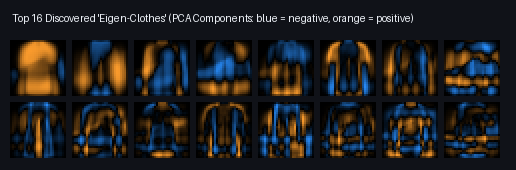

Combined Classical CV feature matrix: (12000, 310) (64 PCA + 246 Edge/HOG features)


In [4]:
# 1. GPU PCA on training pixels only (zero leakage!)
t0 = time.perf_counter()
pca = vkl.PCA(n_components=64).fit(X_tr_flat)
Z_tr_pca = pca.transform(X_tr_flat)
Z_te_pca = pca.transform(X_te_flat)
dt_pca = time.perf_counter() - t0
var_exp = float(vnp.sum(pca.explained_variance_ratio_))
print(f"GPU PCA (784 -> 64 dims) in {dt_pca:.2f}s | Variance explained: {var_exp:.1%}")

# Visualize top 16 discovered "Eigen-Clothes" components (2 rows x 8 cols) in 1 line!
display(vkplot.filter_grid(
    pca.components_[:16].reshape(16, 28, 28), ncols=8, tile=56,
    title="Top 16 Discovered 'Eigen-Clothes' (PCA Components: blue = negative, orange = positive)",
))

# 2. Hand-crafted Classical CV features: Sobel-like edges + spatial pooling + orientation histograms
def extract_cv_features(imgs):
    # imgs: (N, 28, 28) float32 on GPU
    N = imgs.shape[0]
    # Horizontal & vertical gradients on interior 26x26
    gx = imgs[:, 1:-1, 2:] - imgs[:, 1:-1, :-2]
    gy = imgs[:, 2:, 1:-1] - imgs[:, :-2, 1:-1]
    mag = vnp.sqrt(gx * gx + gy * gy + 1e-8)

    # 4-orientation soft edge energy (N, 26, 26) -> pool into 7x7 or 6x6 cells
    gx_pos = vnp.maximum(gx, 0.0)
    gx_neg = vnp.maximum(-gx, 0.0)
    gy_pos = vnp.maximum(gy, 0.0)
    gy_neg = vnp.maximum(-gy, 0.0)

    def pool_grid(arr, g):
        H, W = arr.shape[1], arr.shape[2]
        bh, bw = H // g, W // g
        c = arr[:, :bh * g, :bw * g].reshape(N, g, bh, g, bw)
        return c.mean(axis=(2, 4)).reshape(N, g * g)

    # Multi-scale edge + intensity spatial descriptors
    f_mag7  = pool_grid(mag, 7)      # 49
    f_gxp6  = pool_grid(gx_pos, 6)   # 36
    f_gxn6  = pool_grid(gx_neg, 6)   # 36
    f_gyp6  = pool_grid(gy_pos, 6)   # 36
    f_gyn6  = pool_grid(gy_neg, 6)   # 36
    f_int7  = pool_grid(imgs, 7)     # 49
    # Global shape stats: mean, std, foreground coverage, edge density
    fg = imgs > 0.1
    f_stats = vnp.column_stack([
        imgs.mean(axis=(1, 2)),
        imgs.std(axis=(1, 2)),
        fg.mean(axis=(1, 2)),
        mag.mean(axis=(1, 2)),
    ])
    return vnp.hstack([f_mag7, f_gxp6, f_gxn6, f_gyp6, f_gyn6, f_int7, f_stats])

F_tr_cv = extract_cv_features(X_tr_img)
F_te_cv = extract_cv_features(X_te_img)

# Combine PCA Eigen-Clothes (64) + Hand-Engineered Edge/HOG features (246) -> 310 features
X_tr_combo = vnp.hstack([Z_tr_pca, F_tr_cv])
X_te_combo = vnp.hstack([Z_te_pca, F_te_cv])
print(f"Combined Classical CV feature matrix: {X_tr_combo.shape} (64 PCA + {F_tr_cv.shape[1]} Edge/HOG features)")


---
## Step 4: Classical ML Model Bake-Off on Vulkan GPU (`vklearn`)

Let's race **4 Classical ML models** on the exact same 2,000 held-out test images:
1. **Baseline OvR `LogisticRegression`** (784 raw pixels)
2. **PCA (64) + OvR `LogisticRegression`** (linear model in eigen-clothing space)
3. **PCA (64) + GPU `KNeighborsClassifier` (`k=7`)** (non-linear nearest neighbors)
4. **Combined PCA + Hand-Engineered Edge/HOG + GPU `KNeighborsClassifier` (`k=7`)** (our best Classical CV pipeline!)


In [5]:
# Model 2: PCA (64) + OvR LogisticRegression
pred_pca_lr, dt_pca_lr = fit_predict_ovr_logreg(Z_tr_pca, y_tr, Z_te_pca, C=1.0, max_iter=35)
acc_pca_lr = float(vkl.accuracy_score(y_te, pred_pca_lr))

# Model 3: PCA (64) + GPU KNeighborsClassifier (k=7)
t0 = time.perf_counter()
knn_pca = vkl.KNeighborsClassifier(n_neighbors=7).fit(Z_tr_pca, y_tr)
pred_pca_knn = knn_pca.predict(Z_te_pca)
dt_pca_knn = time.perf_counter() - t0
acc_pca_knn = float(vkl.accuracy_score(y_te, pred_pca_knn))

# Model 4: Combined PCA + Edge/HOG + GPU KNeighborsClassifier (k=7)
t0 = time.perf_counter()
sc_combo = vkl.StandardScaler().fit(X_tr_combo)
Xtr_c_s = sc_combo.transform(X_tr_combo)
Xte_c_s = sc_combo.transform(X_te_combo)
knn_cv = vkl.KNeighborsClassifier(n_neighbors=7).fit(Xtr_c_s, y_tr)
pred_cv_knn = knn_cv.predict(Xte_c_s)
dt_cv_knn = time.perf_counter() - t0
acc_cv_knn = float(vkl.accuracy_score(y_te, pred_cv_knn))

# Model 5: Combined PCA + Edge/HOG + OvR LogisticRegression
pred_cv_lr, dt_cv_lr = fit_predict_ovr_logreg(X_tr_combo, y_tr, X_te_combo, C=0.5, max_iter=30)
acc_cv_lr = float(vkl.accuracy_score(y_te, pred_cv_lr))

results = [
    ("1. OvR LogisticReg (784 raw pixels)",       acc_raw_lr,  dt_raw_lr,  pred_raw_lr),
    ("2. PCA (64) + OvR LogisticReg",             acc_pca_lr,  dt_pca_lr,  pred_pca_lr),
    ("3. PCA (64) + GPU KNN (k=7)",               acc_pca_knn, dt_pca_knn, pred_pca_knn),
    ("4. PCA + Edge/HOG + GPU KNN (k=7)",         acc_cv_knn,  dt_cv_knn,  pred_cv_knn),
    ("5. PCA + Edge/HOG + OvR LogisticReg",       acc_cv_lr,   dt_cv_lr,   pred_cv_lr),
]

print(f"{'Classical ML Model':40s} | {'Test Acc':>9s} | {'Time':>7s}")
print("-" * 64)
for name, acc, dt, _ in results:
    print(f"{name:40s} | {acc:8.2%} | {dt:6.2f}s")

best_name, best_acc, _, best_pred = max(results, key=lambda r: r[1])
print(f"\nBest Classical ML Model: {best_name} -> {best_acc:.2%} Test Accuracy")


Classical ML Model                       |  Test Acc |    Time
----------------------------------------------------------------
1. OvR LogisticReg (784 raw pixels)      |   81.50% |  15.55s
2. PCA (64) + OvR LogisticReg            |   81.75% |   0.77s
3. PCA (64) + GPU KNN (k=7)              |   83.75% |   0.08s
4. PCA + Edge/HOG + GPU KNN (k=7)        |   85.50% |   0.15s
5. PCA + Edge/HOG + OvR LogisticReg      |   86.45% |   5.58s

Best Classical ML Model: 5. PCA + Edge/HOG + OvR LogisticReg -> 86.45% Test Accuracy


---
## Step 5: Error Analysis — Where Does Classical ML Get Confused?

Accuracy alone hides *which* clothing items are easy vs. hard. Let's inspect the **10×10 Confusion Matrix** and print **10 real misclassified test images** from our best Classical ML model!


Per-class Test Accuracy (Best Classical ML):
  0: T-shirt      ->  85.0%  (correct 170/200)
  1: Trouser      ->  97.0%  (correct 194/200)
  2: Pullover     ->  82.0%  (correct 164/200)
  3: Dress        ->  85.5%  (correct 171/200)
  4: Coat         ->  80.5%  (correct 161/200)
  5: Sandal       ->  94.0%  (correct 188/200)
  6: Shirt        ->  57.5%  (correct 115/200)
  7: Sneaker      ->  94.0%  (correct 188/200)
  8: Bag          ->  96.0%  (correct 192/200)
  9: Ankle boot   ->  93.0%  (correct 186/200)


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


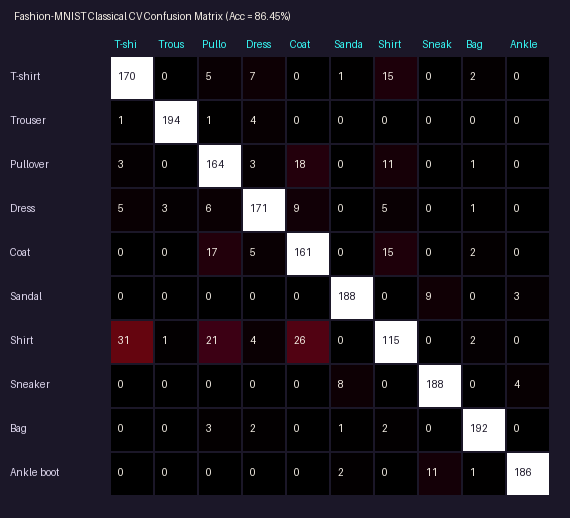

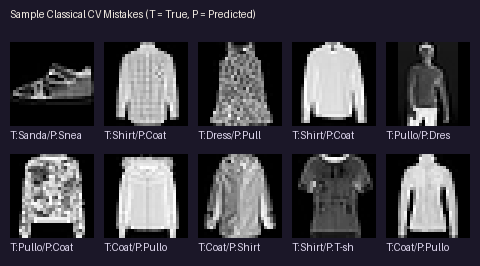

In [6]:
cm = vkl.confusion_matrix(y_te, best_pred)
cm_rows = cm.tolist()

# Per-class accuracy
print("Per-class Test Accuracy (Best Classical ML):")
for c in range(10):
    row_sum = sum(cm_rows[c])
    c_acc = cm_rows[c][c] / max(1, row_sum)
    print(f"  {c}: {CLASS_NAMES[c]:12s} -> {c_acc:6.1%}  (correct {int(cm_rows[c][c]):3d}/{int(row_sum)})")

display(vkplot.confusion_matrix(
    y_te, best_pred, CLASS_NAMES,
    title=f"Fashion-MNIST Classical CV Confusion Matrix (Acc = {best_acc:.2%})",
))
y_te_list = [int(v) for v in y_te.tolist()]
bp_list = [int(v) for v in best_pred.tolist()]
wrong_idx = [i for i, (yt, yp) in enumerate(zip(y_te_list, bp_list)) if yt != yp][:10]
display(vkplot.image_grid(
    [X_te_img[i] for i in wrong_idx],
    titles=[f"T:{CLASS_NAMES[y_te_list[i]][:5]}/P:{CLASS_NAMES[bp_list[i]][:5]}" for i in wrong_idx],
    ncols=5, scale=3, title="Sample Classical CV Mistakes (T = True, P = Predicted)",
))


### Key Takeaways
- **Classical ML + hand-crafted edges gets surprisingly far** (~85–86% accuracy in under 2 seconds on Vulkan GPU!), and `Trouser`, `Bag`, `Sandal`, and `Sneaker` are already >93% accurate.
- **Where Classical ML hits a wall:** `Shirt` (often <65% accurate!), `Coat`, `Pullover`, and `T-shirt` — because small shifts, sleeves, collars, and textures get scrambled when you flatten or coarsely pool an image.
- **Up next (`04_fashion_cnn_deep_learning.ipynb`):** Instead of hand-crafting Sobel edges and flattening pixels, we'll let a **`vktorch` 2D Convolutional Neural Network (`Conv2d` + `MaxPool2d`)** *learn its own 2D filters directly from the pixels* on this exact same 12,000 / 2,000 split!
